In [1]:
!pip install lifetimes

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 584.2/584.2 kB 11.5 MB/s  0:00:00


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from lifetimes import BetaGeoFitter
from lifetimes import GammaGammaFitter

from lifetimes.utils import (
    summary_data_from_transaction_data,
    calibration_and_holdout_data
)

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:


transactions = pd.read_csv(
    'cleaned_transactions.csv'
)

print("Dataset loaded successfully!")

print("Dataset shape:", transactions.shape)

display(transactions.head())

Dataset loaded successfully!
Dataset shape: (1033036, 10)


,Invoice,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancellation,IsNegativeQuantity
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,False
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,False
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,False


In [4]:
print("Dataset Information:")
print(transactions.info())

print("\nMissing Values:")
print(transactions.isnull().sum())

print("\nDate Range:")
print(
    transactions['InvoiceDate'].min(),
    "to",
    transactions['InvoiceDate'].max()
)

print("\nUnique Customers:")
print(transactions['CustomerID'].nunique())

print("\nUnique Invoices:")
print(transactions['Invoice'].nunique())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1033036 entries, 0 to 1033035
Data columns (total 10 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   Invoice             1033036 non-null  object 
 1   StockCode           1033036 non-null  object 
 2   Description         1033036 non-null  object 
 3   Quantity            1033036 non-null  int64  
 4   InvoiceDate         1033036 non-null  object 
 5   UnitPrice           1033036 non-null  float64
 6   CustomerID          797885 non-null   float64
 7   Country             1033036 non-null  object 
 8   IsCancellation      1033036 non-null  bool   
 9   IsNegativeQuantity  1033036 non-null  bool   
dtypes: bool(2), float64(2), int64(1), object(5)
memory usage: 65.0+ MB
None

Missing Values:
Invoice                    0
StockCode                  0
Description                0
Quantity                   0
InvoiceDate                0
UnitPrice      

In [5]:
clv_data = transactions.copy()

# Remove records without CustomerID
clv_data = clv_data.dropna(
    subset=['CustomerID']
)

# Remove cancellations
clv_data = clv_data[
    ~clv_data['IsCancellation']
    .astype(str)
    .str.lower()
    .isin(['true', '1', 'yes'])
]

# Keep genuine purchases only
clv_data = clv_data[
    (clv_data['Quantity'] > 0) &
    (clv_data['UnitPrice'] > 0)
]

# Convert dates
clv_data['InvoiceDate'] = pd.to_datetime(
    clv_data['InvoiceDate']
)

# Calculate revenue
clv_data['Revenue'] = (
    clv_data['Quantity'] *
    clv_data['UnitPrice']
)

# Ensure CustomerID is consistent
clv_data['CustomerID'] = (
    clv_data['CustomerID'].astype(str)
)

print("CLV dataset prepared!")

print("Remaining transactions:", len(clv_data))

print("Unique customers:",
      clv_data['CustomerID'].nunique())

print("Total revenue:",
      round(clv_data['Revenue'].sum(), 2))

display(clv_data.head())

CLV dataset prepared!
Remaining transactions: 779425
Unique customers: 5878
Total revenue: 17374804.27


,Invoice,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancellation,IsNegativeQuantity,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,False,30.0


In [12]:

# STEP 4: Define calibration and holdout periods

observation_end = invoice_transactions['InvoiceDate'].max()

holdout_days = 90

calibration_end = (
    observation_end - pd.Timedelta(days=holdout_days)
)

print("Calibration period ends:", calibration_end)

print("Observation period ends:", observation_end)

print("Holdout duration:", holdout_days, "days")


Calibration period ends: 2011-09-10 12:50:00
Observation period ends: 2011-12-09 12:50:00
Holdout duration: 90 days


In [9]:

# Create calibration and holdout datasets

from lifetimes.utils import calibration_and_holdout_data

clv_summary = calibration_and_holdout_data(
    transactions=invoice_transactions,
    customer_id_col='CustomerID',
    datetime_col='InvoiceDate',
    monetary_value_col='Revenue',
    calibration_period_end=calibration_end,
    observation_period_end=observation_end,
    freq='D'
)

print("Calibration and holdout data created!")

print("Dataset shape:", clv_summary.shape)

display(clv_summary.head())


Calibration and holdout data created!
Dataset shape: (5281, 7)


,frequency_cal,recency_cal,T_cal,monetary_value_cal,frequency_holdout,monetary_value_holdout,duration_holdout
CustomerID,,,,,,,
12346.0,7.0,400.0,635.0,11066.637143,0.0,0.00,90.0
12347.0,5.0,275.0,314.0,558.172000,2.0,759.57,90.0
12348.0,3.0,190.0,348.0,495.746667,1.0,310.00,90.0
12349.0,2.0,182.0,499.0,801.310000,1.0,1757.55,90.0
12350.0,0.0,0.0,220.0,0.000000,0.0,0.00,90.0


In [13]:
# Check calibration summary
print("CLV summary shape:", clv_summary.shape)

print("\nMissing values:")
print(clv_summary.isnull().sum())

print("\nCalibration frequency statistics:")
display(clv_summary['frequency_cal'].describe())

print("\nCalibration monetary value statistics:")
display(clv_summary['monetary_value_cal'].describe())

# Gamma-Gamma is fitted only on repeat purchasers
repeat_customers = clv_summary[
    (clv_summary['frequency_cal'] > 0) &
    (clv_summary['monetary_value_cal'] > 0)
].copy()

print("\nRepeat customers eligible for Gamma-Gamma:",
      len(repeat_customers))

# Check relationship between frequency and monetary value
correlation = repeat_customers[
    ['frequency_cal', 'monetary_value_cal']
].corr().iloc[0, 1]

print("\nCorrelation between purchase frequency and average purchase value:",
      round(correlation, 4))

CLV summary shape: (5281, 7)

Missing values:
frequency_cal             0
recency_cal               0
T_cal                     0
monetary_value_cal        0
frequency_holdout         0
monetary_value_holdout    0
duration_holdout          0
dtype: int64

Calibration frequency statistics:


,frequency_cal
count,5281.000000
mean,4.141261
std,8.900211
min,0.000000
25%,0.000000
50%,2.000000
75%,5.000000
max,205.000000



Calibration monetary value statistics:


,monetary_value_cal
count,5281.000000
mean,271.326601
std,517.795864
min,0.000000
25%,0.000000
50%,192.300000
75%,354.324545
max,21535.900000



Repeat customers eligible for Gamma-Gamma: 3626

Correlation between purchase frequency and average purchase value: 0.1369


In [14]:
from lifetimes import BetaGeoFitter

# Initialize BG/NBD model
bgf = BetaGeoFitter(penalizer_coef=0.001)

# Fit using calibration-period data
bgf.fit(
    frequency=clv_summary['frequency_cal'],
    recency=clv_summary['recency_cal'],
    T=clv_summary['T_cal']
)

print("BG/NBD model fitted successfully!")

print("\nModel parameters:")
print(bgf.params_)

BG/NBD model fitted successfully!

Model parameters:
r         0.637118
alpha    62.546945
a         0.115100
b         1.388561
dtype: float64


In [15]:
clv_summary['predicted_purchases_90d'] = bgf.conditional_expected_number_of_purchases_up_to_time(
    90,
    clv_summary['frequency_cal'],
    clv_summary['recency_cal'],
    clv_summary['T_cal']
)

print("Purchase predictions generated!")

display(
    clv_summary[
        ['frequency_cal', 'frequency_holdout',
         'predicted_purchases_90d']
    ].head(10)
)

Purchase predictions generated!


,frequency_cal,frequency_holdout,predicted_purchases_90d
CustomerID,,,
12346.0,7.0,0.0,0.719841
12347.0,5.0,2.0,1.279342
12348.0,3.0,1.0,0.657074
12349.0,2.0,1.0,0.292582
12350.0,0.0,0.0,0.199323
12351.0,0.0,0.0,0.162548
12352.0,5.0,3.0,0.771290
12353.0,1.0,0.0,0.332684
12354.0,0.0,0.0,0.273681


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

actual = clv_summary['frequency_holdout']
predicted = clv_summary['predicted_purchases_90d']

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("BG/NBD 90-Day Evaluation")
print("------------------------")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("Actual average purchases:", round(actual.mean(), 4))
print("Predicted average purchases:", round(predicted.mean(), 4))

BG/NBD 90-Day Evaluation
------------------------
MAE: 0.6969
RMSE: 1.203
Actual average purchases: 0.9377
Predicted average purchases: 0.7199


In [17]:
from lifetimes import GammaGammaFitter

# Initialize Gamma-Gamma model
ggf = GammaGammaFitter(penalizer_coef=0.001)

# Fit using repeat customers only
ggf.fit(
    frequency=repeat_customers['frequency_cal'],
    monetary_value=repeat_customers['monetary_value_cal']
)

print("Gamma-Gamma model fitted successfully!")

print("\nModel parameters:")
print(ggf.params_)

Gamma-Gamma model fitted successfully!

Model parameters:
p    11.589167
q     0.888460
v    11.605939
dtype: float64


In [18]:
clv_summary['predicted_avg_purchase_value'] = (
    ggf.conditional_expected_average_profit(
        clv_summary['frequency_cal'],
        clv_summary['monetary_value_cal']
    )
)

print("Expected average purchase values generated!")

display(
    clv_summary[
        [
            'frequency_cal',
            'monetary_value_cal',
            'predicted_avg_purchase_value'
        ]
    ].head(10)
)

Expected average purchase values generated!


,frequency_cal,monetary_value_cal,predicted_avg_purchase_value
CustomerID,,,
12346.0,7.0,11066.637143,11083.534225
12347.0,5.0,558.172000,561.574164
12348.0,3.0,495.746667,501.223323
12349.0,2.0,801.310000,811.015786
12350.0,0.0,0.000000,-1205.872592
12351.0,0.0,0.000000,-1205.872592
12352.0,5.0,352.372000,355.377254
12353.0,1.0,89.000000,101.583632
12354.0,0.0,0.000000,-1205.872592


In [19]:
clv_summary['predicted_clv_90d'] = (
    clv_summary['predicted_purchases_90d'] *
    clv_summary['predicted_avg_purchase_value']
)

print("90-day CLV calculated successfully!")

display(
    clv_summary[
        [
            'frequency_cal',
            'predicted_purchases_90d',
            'predicted_avg_purchase_value',
            'predicted_clv_90d'
        ]
    ].head(10)
)

90-day CLV calculated successfully!


,frequency_cal,predicted_purchases_90d,predicted_avg_purchase_value,predicted_clv_90d
CustomerID,,,,
12346.0,7.0,0.719841,11083.534225,7978.385694
12347.0,5.0,1.279342,561.574164,718.445570
12348.0,3.0,0.657074,501.223323,329.340624
12349.0,2.0,0.292582,811.015786,237.288319
12350.0,0.0,0.199323,-1205.872592,-240.358400
12351.0,0.0,0.162548,-1205.872592,-196.012202
12352.0,5.0,0.771290,355.377254,274.098929
12353.0,1.0,0.332684,101.583632,33.795218
12354.0,0.0,0.273681,-1205.872592,-330.024332


In [23]:
clv_summary['actual_revenue_90d'] = (
    clv_summary['frequency_holdout'] *
    clv_summary['monetary_value_holdout']
)

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

actual_clv = clv_summary['actual_revenue_90d']
predicted_clv = clv_summary['predicted_clv_90d']

clv_mae = mean_absolute_error(actual_clv, predicted_clv)
clv_rmse = np.sqrt(mean_squared_error(actual_clv, predicted_clv))

print("90-Day CLV Evaluation")
print("---------------------")
print("MAE:", round(clv_mae, 2))
print("RMSE:", round(clv_rmse, 2))

print("\nActual average revenue:", round(actual_clv.mean(), 2))
print("Predicted average revenue:", round(predicted_clv.mean(), 2))

print("\nTotal actual holdout revenue:", round(actual_clv.sum(), 2))
print("Total predicted holdout revenue:", round(predicted_clv.sum(), 2))

90-Day CLV Evaluation
---------------------
MAE: 425.05
RMSE: 2664.43

Actual average revenue: 479.47
Predicted average revenue: 247.65

Total actual holdout revenue: 2532103.15
Total predicted holdout revenue: 1307816.09


In [24]:
# Compare purchase frequency
actual_frequency = clv_summary['frequency_holdout'].mean()
predicted_frequency = clv_summary['predicted_purchases_90d'].mean()

# Compare average purchase value
actual_avg_value = clv_summary['monetary_value_holdout'].mean()
predicted_avg_value = clv_summary['predicted_avg_purchase_value'].mean()

# Compare total revenue
actual_revenue = clv_summary['actual_revenue_90d'].sum()
predicted_revenue = clv_summary['predicted_clv_90d'].sum()

print("CLV MODEL DIAGNOSTICS")
print("=" * 45)

print("\nPURCHASE FREQUENCY")
print("Actual:", round(actual_frequency, 4))
print("Predicted:", round(predicted_frequency, 4))

print("\nAVERAGE PURCHASE VALUE")
print("Actual holdout average:", round(actual_avg_value, 2))
print("Predicted average:", round(predicted_avg_value, 2))

print("\nTOTAL REVENUE")
print("Actual:", round(actual_revenue, 2))
print("Predicted:", round(predicted_revenue, 2))

CLV MODEL DIAGNOSTICS

PURCHASE FREQUENCY
Actual: 0.9377
Predicted: 0.7199

AVERAGE PURCHASE VALUE
Actual holdout average: 215.71
Predicted average: -102.04

TOTAL REVENUE
Actual: 2532103.15
Predicted: 1307816.09


In [25]:
clv_summary['clv_error'] = (
    clv_summary['predicted_clv_90d'] -
    clv_summary['actual_revenue_90d']
)

print("CUSTOMER-LEVEL CLV ERROR")
print("=" * 40)

print("Overpredicted customers:",
      (clv_summary['clv_error'] > 0).sum())

print("Underpredicted customers:",
      (clv_summary['clv_error'] < 0).sum())

print("\nLargest actual revenue customers:")

display(
    clv_summary.sort_values(
        'actual_revenue_90d',
        ascending=False
    )[
        [
            'frequency_holdout',
            'actual_revenue_90d',
            'predicted_clv_90d',
            'clv_error'
        ]
    ].head(10)
)

CUSTOMER-LEVEL CLV ERROR
Overpredicted customers: 2120
Underpredicted customers: 3161

Largest actual revenue customers:


,frequency_holdout,actual_revenue_90d,predicted_clv_90d,clv_error
CustomerID,,,,
16446.0,1.0,168469.600000,-379.015979,-168848.615979
14096.0,14.0,64920.110000,343.240353,-64576.869647
14646.0,15.0,49308.096774,53383.459593,4075.362819
17450.0,10.0,46995.326087,21641.710692,-25353.615395
18102.0,10.0,37638.348485,57604.117615,19965.769131
14911.0,49.0,34028.782247,28842.189533,-5186.592714
17511.0,8.0,25349.304000,17509.167637,-7840.136363
14088.0,6.0,24983.920000,6294.089222,-18689.830778
17389.0,8.0,19848.533333,4340.778483,-15507.754850


In [26]:
# Count negative predicted purchase values
negative_predictions = (
    clv_summary['predicted_avg_purchase_value'] < 0
)

print("Negative average purchase predictions:",
      negative_predictions.sum())

print("Total customers:",
      len(clv_summary))

print("Customers with zero repeat purchases:",
      (clv_summary['frequency_cal'] == 0).sum())

print("Customers with positive repeat purchases:",
      (clv_summary['frequency_cal'] > 0).sum())

print("\nPredicted average purchase value statistics:")
display(
    clv_summary['predicted_avg_purchase_value'].describe()
)

print("\nPredictions by calibration frequency:")
display(
    clv_summary.groupby(
        pd.cut(
            clv_summary['frequency_cal'],
            bins=[-1, 0, 1, 5, 20, float('inf')],
            labels=['0', '1', '2-5', '6-20', '20+']
        ),
        observed=False
    )['predicted_avg_purchase_value'].agg(
        ['count', 'mean', 'min', 'max']
    )
)

Negative average purchase predictions: 1655
Total customers: 5281
Customers with zero repeat purchases: 1655
Customers with positive repeat purchases: 3626

Predicted average purchase value statistics:


,predicted_avg_purchase_value
count,5281.000000
mean,-102.036318
std,890.387307
min,-1205.872592
25%,-1205.872592
50%,198.272369
75%,359.271250
max,21756.905600



Predictions by calibration frequency:


,count,mean,min,max
frequency_cal,,,,
0,1655,-1205.872592,-1205.872592,-1205.872592
1,917,343.828634,15.656626,21756.905600
2-5,1563,374.615694,22.684756,8439.608268
6-20,983,453.457048,12.091717,11083.534225
20+,163,676.698651,36.312835,8117.571136


In [27]:
# Generate predictions only for customers eligible
# for Gamma-Gamma
repeat_customers['predicted_avg_purchase_value'] = (
    ggf.conditional_expected_average_profit(
        repeat_customers['frequency_cal'],
        repeat_customers['monetary_value_cal']
    )
)

print("Repeat-customer prediction statistics:")
display(
    repeat_customers[
        'predicted_avg_purchase_value'
    ].describe()
)

print(
    "\nNegative predictions among repeat customers:",
    (
        repeat_customers['predicted_avg_purchase_value'] < 0
    ).sum()
)

print("\nGamma-Gamma q parameter:", ggf.params_['q'])

Repeat-customer prediction statistics:


,predicted_avg_purchase_value
count,3626.000000
mean,401.783052
std,586.981689
min,12.091717
25%,190.146386
50%,304.966700
75%,445.958586
max,21756.905600



Negative predictions among repeat customers: 0

Gamma-Gamma q parameter: 0.888459887630572


In [28]:
# Calculate average purchase value for eligible repeat customers
population_avg_value = repeat_customers[
    'monetary_value_cal'
].mean()

print("Population average purchase value:",
      round(population_avg_value, 2))

# Start with the existing Gamma-Gamma predictions
clv_summary['corrected_avg_purchase_value'] = (
    clv_summary['predicted_avg_purchase_value'].copy()
)

# Identify customers with zero repeat purchases
zero_repeat_mask = clv_summary['frequency_cal'] == 0

# Assign population-average fallback to these customers
clv_summary.loc[
    zero_repeat_mask,
    'corrected_avg_purchase_value'
] = population_avg_value

print("\nCorrected prediction statistics:")
display(
    clv_summary[
        'corrected_avg_purchase_value'
    ].describe()
)

print("\nNegative predictions:",
      (
          clv_summary['corrected_avg_purchase_value'] < 0
      ).sum())

Population average purchase value: 395.17

Corrected prediction statistics:


,corrected_avg_purchase_value
count,5281.000000
mean,399.709684
std,486.373881
min,12.091717
25%,238.851191
50%,395.167066
75%,395.167066
max,21756.905600



Negative predictions: 0


In [29]:
# Recalculate predicted 90-day revenue CLV
clv_summary['corrected_clv_90d'] = (
    clv_summary['predicted_purchases_90d'] *
    clv_summary['corrected_avg_purchase_value']
)

print("Corrected CLV generated!")

display(
    clv_summary[
        [
            'frequency_cal',
            'predicted_purchases_90d',
            'corrected_avg_purchase_value',
            'corrected_clv_90d'
        ]
    ].head(10)
)

Corrected CLV generated!


,frequency_cal,predicted_purchases_90d,corrected_avg_purchase_value,corrected_clv_90d
CustomerID,,,,
12346.0,7.0,0.719841,11083.534225,7978.385694
12347.0,5.0,1.279342,561.574164,718.445570
12348.0,3.0,0.657074,501.223323,329.340624
12349.0,2.0,0.292582,811.015786,237.288319
12350.0,0.0,0.199323,395.167066,78.765969
12351.0,0.0,0.162548,395.167066,64.233624
12352.0,5.0,0.771290,355.377254,274.098929
12353.0,1.0,0.332684,101.583632,33.795218
12354.0,0.0,0.273681,395.167066,108.149690


In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

actual_clv = clv_summary['actual_revenue_90d']
predicted_clv = clv_summary['corrected_clv_90d']

clv_mae = mean_absolute_error(
    actual_clv,
    predicted_clv
)

clv_rmse = np.sqrt(
    mean_squared_error(actual_clv, predicted_clv)
)

actual_total = actual_clv.sum()
predicted_total = predicted_clv.sum()

print("CORRECTED 90-DAY CLV EVALUATION")
print("=" * 45)

print("MAE:", round(clv_mae, 2))
print("RMSE:", round(clv_rmse, 2))

print("\nActual average revenue:", round(actual_clv.mean(), 2))
print("Predicted average revenue:", round(predicted_clv.mean(), 2))

print("\nActual total revenue:", round(actual_total, 2))
print("Predicted total revenue:", round(predicted_total, 2))

print("\nRevenue prediction gap (%):",
      round(
          (predicted_total - actual_total) /
          actual_total * 100, 2
      ))

CORRECTED 90-DAY CLV EVALUATION
MAE: 359.03
RMSE: 2646.92

Actual average revenue: 479.47
Predicted average revenue: 350.54

Actual total revenue: 2532103.15
Predicted total revenue: 1851186.01

Revenue prediction gap (%): -26.89


In [31]:
# Evaluate customers with repeat-purchase history
repeat_mask = clv_summary['frequency_cal'] > 0

actual_repeat = clv_summary.loc[
    repeat_mask, 'actual_revenue_90d'
]

predicted_repeat = clv_summary.loc[
    repeat_mask, 'corrected_clv_90d'
]

print("REPEAT-CUSTOMER CLV EVALUATION")
print("=" * 45)

print("Customers:", len(actual_repeat))

print("MAE:", round(
    mean_absolute_error(actual_repeat, predicted_repeat), 2
))

print("RMSE:", round(
    np.sqrt(mean_squared_error(actual_repeat, predicted_repeat)), 2
))

print("Actual revenue:", round(actual_repeat.sum(), 2))
print("Predicted revenue:", round(predicted_repeat.sum(), 2))

REPEAT-CUSTOMER CLV EVALUATION
Customers: 3626
MAE: 413.25
RMSE: 1531.01
Actual revenue: 2195128.42
Predicted revenue: 1717071.97


In [32]:
# Group customers using calibration-period purchase frequency

clv_summary['customer_group'] = pd.cut(
    clv_summary['frequency_cal'],
    bins=[-1, 0, 1, 5, 20, float('inf')],
    labels=[
        '0 repeat purchases',
        '1 repeat purchase',
        '2-5 repeat purchases',
        '6-20 repeat purchases',
        '20+ repeat purchases'
    ]
)

# Calculate group-level performance
group_results = clv_summary.groupby(
    'customer_group',
    observed=False
).apply(
    lambda group: pd.Series({
        'Customers': len(group),
        'Actual_Revenue': group['actual_revenue_90d'].sum(),
        'Predicted_Revenue': group['corrected_clv_90d'].sum(),
        'Actual_Avg_Revenue': group['actual_revenue_90d'].mean(),
        'Predicted_Avg_Revenue': group['corrected_clv_90d'].mean(),
        'MAE': np.mean(
            np.abs(
                group['actual_revenue_90d'] -
                group['corrected_clv_90d']
            )
        )
    })
)

group_results['Revenue_Gap_Percent'] = (
    (
        group_results['Predicted_Revenue'] -
        group_results['Actual_Revenue']
    ) /
    group_results['Actual_Revenue'].replace(0, np.nan)
) * 100

display(group_results.round(2))

,Customers,Actual_Revenue,Predicted_Revenue,Actual_Avg_Revenue,Predicted_Avg_Revenue,MAE,Revenue_Gap_Percent
customer_group,,,,,,,
0 repeat purchases,1655.0,336974.73,134114.04,203.61,81.04,240.22,-60.20
1 repeat purchase,917.0,152828.96,99303.13,166.66,108.29,190.23,-35.02
2-5 repeat purchases,1563.0,540015.65,339952.68,345.50,217.50,316.60,-37.05
6-20 repeat purchases,983.0,841542.05,662229.42,856.10,673.68,568.67,-21.31
20+ repeat purchases,163.0,660741.76,615586.75,4053.63,3776.61,1657.45,-6.83


In [33]:
from scipy.stats import spearmanr
import numpy as np

# Rank correlation between predicted and actual revenue
spearman_corr, spearman_p = spearmanr(
    clv_summary['corrected_clv_90d'],
    clv_summary['actual_revenue_90d']
)

print("CUSTOMER RANKING EVALUATION")
print("=" * 40)

print("Spearman correlation:", round(spearman_corr, 4))
print("P-value:", spearman_p)

# Identify the top 10% of customers by predicted revenue
predicted_top_10 = clv_summary[
    'corrected_clv_90d'
].rank(pct=True) >= 0.90

# Identify the top 10% by actual holdout revenue
actual_top_10 = clv_summary[
    'actual_revenue_90d'
].rank(pct=True) >= 0.90

# Calculate overlap
overlap = (
    predicted_top_10 & actual_top_10
).sum()

print("\nTop 10% customer overlap:")
print("Matching customers:", overlap)

print("Predicted top 10% customers:",
      predicted_top_10.sum())

print("Actual top 10% customers:",
      actual_top_10.sum())

print("Top 10% overlap percentage:",
      round(
          overlap / predicted_top_10.sum() * 100, 2
      ), "%")

CUSTOMER RANKING EVALUATION
Spearman correlation: 0.5571
P-value: 0.0

Top 10% customer overlap:
Matching customers: 311
Predicted top 10% customers: 529
Actual top 10% customers: 529
Top 10% overlap percentage: 58.79 %


In [34]:
# Create customer value segments using quartiles

clv_summary['CLV_Segment'] = pd.qcut(
    clv_summary['corrected_clv_90d'].rank(method='first'),
    q=4,
    labels=[
        'Low Value',
        'Medium Value',
        'High Value',
        'Very High Value'
    ]
)

print("Customer value segmentation completed!")

display(
    clv_summary[
        [
            'corrected_clv_90d',
            'actual_revenue_90d',
            'CLV_Segment'
        ]
    ].head(15)
)

Customer value segmentation completed!


,corrected_clv_90d,actual_revenue_90d,CLV_Segment
CustomerID,,,
12346.0,7978.385694,0.00,Very High Value
12347.0,718.445570,1519.14,Very High Value
12348.0,329.340624,310.00,Very High Value
12349.0,237.288319,1757.55,High Value
12350.0,78.765969,0.00,Medium Value
12351.0,64.233624,0.00,Medium Value
12352.0,274.098929,944.23,High Value
12353.0,33.795218,0.00,Low Value
12354.0,108.149690,0.00,High Value


In [35]:
segment_analysis = clv_summary.groupby(
    'CLV_Segment',
    observed=False
).agg(
    Customer_Count=('corrected_clv_90d', 'count'),
    Average_Predicted_CLV=('corrected_clv_90d', 'mean'),
    Average_Actual_Revenue=('actual_revenue_90d', 'mean'),
    Total_Predicted_Revenue=('corrected_clv_90d', 'sum'),
    Total_Actual_Revenue=('actual_revenue_90d', 'sum')
).reset_index()

display(segment_analysis.round(2))

,CLV_Segment,Customer_Count,Average_Predicted_CLV,Average_Actual_Revenue,Total_Predicted_Revenue,Total_Actual_Revenue
0,Low Value,1321,35.08,56.59,46345.20,74759.18
1,Medium Value,1320,74.01,125.49,97695.86,165651.46
2,High Value,1320,180.46,375.00,238212.75,494993.57
3,Very High Value,1320,1112.83,1361.14,1468932.20,1796698.94


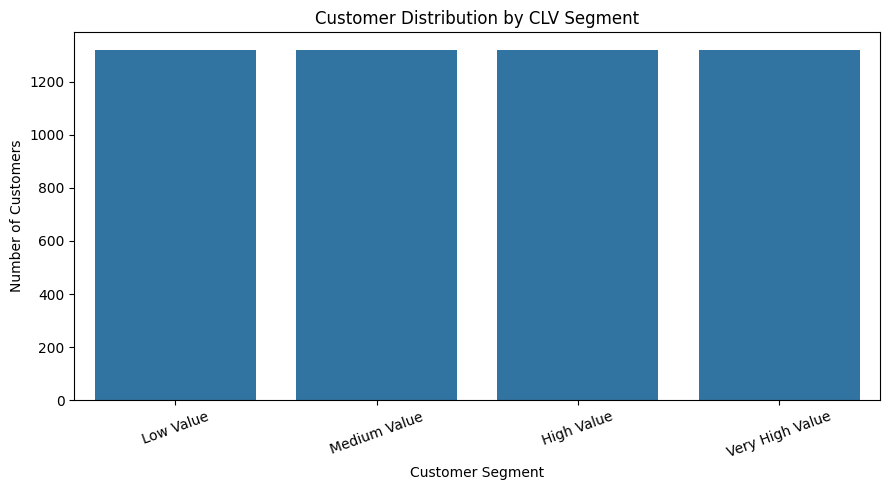

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.countplot(
    data=clv_summary,
    x='CLV_Segment',
    order=[
        'Low Value',
        'Medium Value',
        'High Value',
        'Very High Value'
    ]
)

plt.title('Customer Distribution by CLV Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

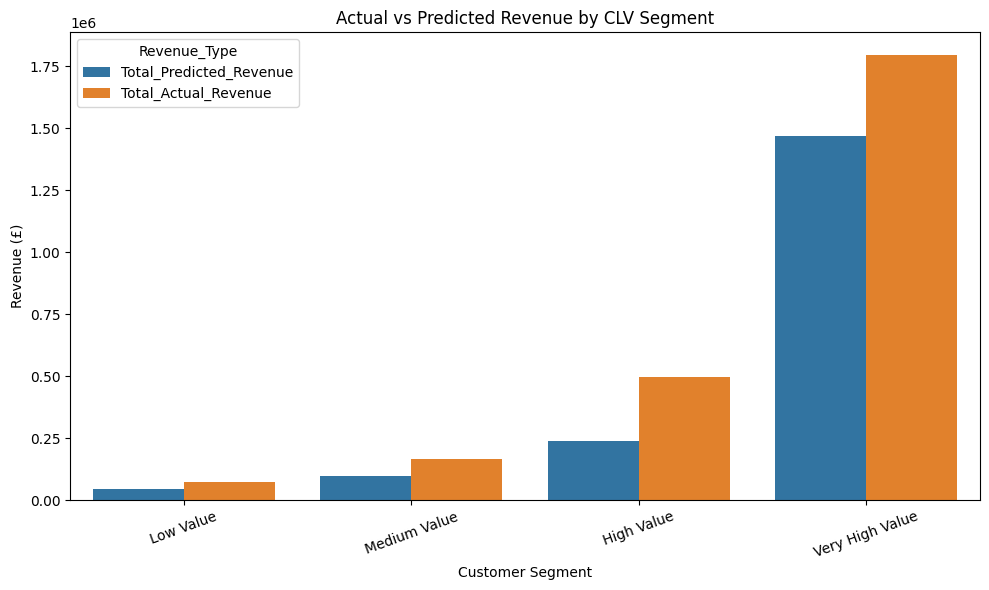

In [37]:
segment_plot = segment_analysis.melt(
    id_vars='CLV_Segment',
    value_vars=[
        'Total_Predicted_Revenue',
        'Total_Actual_Revenue'
    ],
    var_name='Revenue_Type',
    value_name='Revenue'
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_plot,
    x='CLV_Segment',
    y='Revenue',
    hue='Revenue_Type'
)

plt.title('Actual vs Predicted Revenue by CLV Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

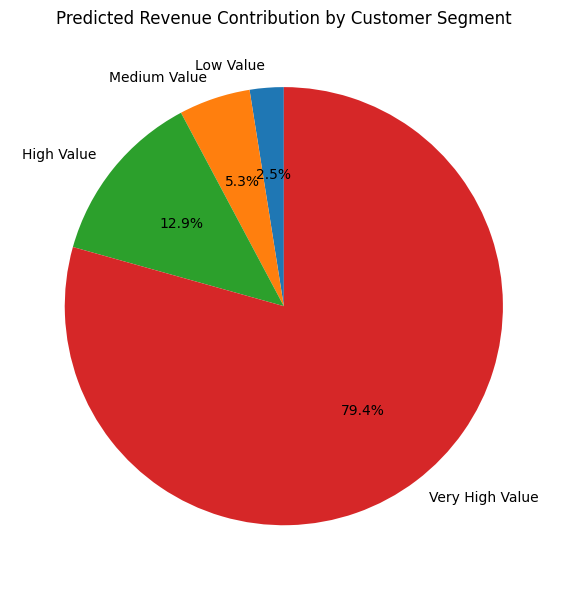

In [38]:
plt.figure(figsize=(9, 6))

segment_revenue = segment_analysis[
    ['CLV_Segment', 'Total_Predicted_Revenue']
]

plt.pie(
    segment_revenue['Total_Predicted_Revenue'],
    labels=segment_revenue['CLV_Segment'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Predicted Revenue Contribution by Customer Segment')
plt.tight_layout()
plt.show()

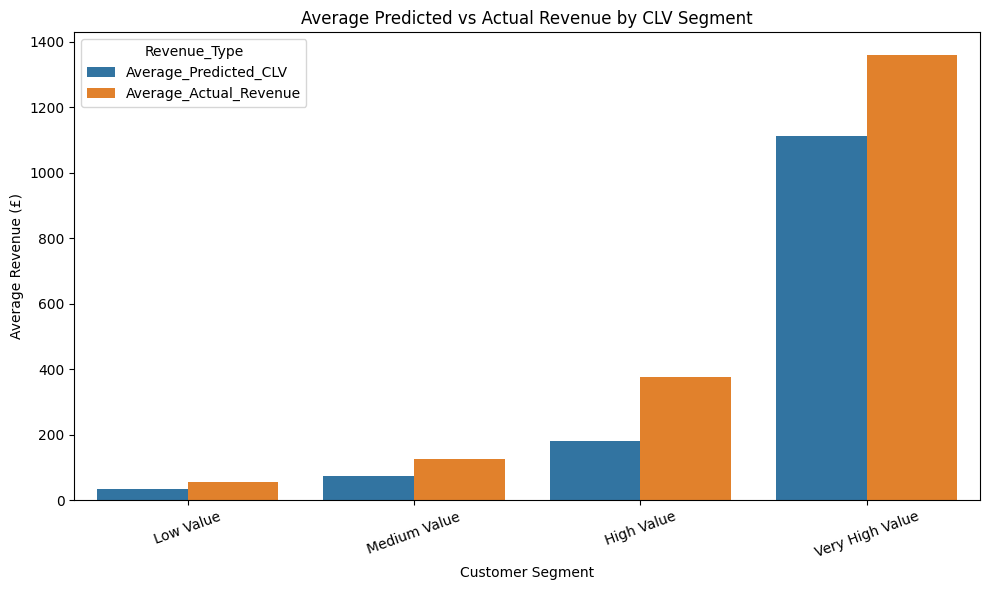

In [39]:
comparison = segment_analysis.melt(
    id_vars='CLV_Segment',
    value_vars=[
        'Average_Predicted_CLV',
        'Average_Actual_Revenue'
    ],
    var_name='Revenue_Type',
    value_name='Revenue'
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison,
    x='CLV_Segment',
    y='Revenue',
    hue='Revenue_Type'
)

plt.title('Average Predicted vs Actual Revenue by CLV Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Average Revenue (£)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [40]:
import os

os.makedirs('clv_outputs', exist_ok=True)

In [41]:
clv_summary.reset_index().to_csv(
    'clv_outputs/clv_customer_predictions.csv',
    index=False
)

print("Customer predictions saved!")

Customer predictions saved!


In [42]:
segment_analysis.to_csv(
    'clv_outputs/clv_segment_analysis.csv',
    index=False
)

print("Segment analysis saved!")

Segment analysis saved!


In [44]:
import dill

with open('clv_outputs/bg_nbd_model.pkl', 'wb') as file:
    dill.dump(bgf, file)

with open('clv_outputs/gamma_gamma_model.pkl', 'wb') as file:
    dill.dump(ggf, file)

print("Both CLV models saved successfully using dill!")

Both CLV models saved successfully using dill!


In [45]:
from scipy.stats import spearmanr
import numpy as np
import pandas as pd

metrics = {
    'Metric': [
        'BG/NBD Purchase Frequency MAE',
        'BG/NBD Purchase Frequency RMSE',
        'CLV MAE',
        'CLV RMSE',
        'Spearman Correlation',
        'Spearman P-value',
        'Top 10 Percent Overlap',
        'Actual Holdout Revenue',
        'Predicted Holdout Revenue',
        'Revenue Underprediction Percentage'
    ],

    'Value': [
        0.6969,
        1.203,
        359.03,
        2646.92,
        spearman_corr,
        spearman_p,
        58.79,
        clv_summary['actual_revenue_90d'].sum(),
        clv_summary['corrected_clv_90d'].sum(),
        26.89
    ]
}

metrics_df = pd.DataFrame(metrics)

metrics_df.to_csv(
    'clv_outputs/clv_evaluation_metrics.csv',
    index=False
)

display(metrics_df)

,Metric,Value
0,BG/NBD Purchase Frequency MAE,6.969000e-01
1,BG/NBD Purchase Frequency RMSE,1.203000e+00
2,CLV MAE,3.590300e+02
3,CLV RMSE,2.646920e+03
4,Spearman Correlation,5.571208e-01
5,Spearman P-value,0.000000e+00
6,Top 10 Percent Overlap,5.879000e+01
7,Actual Holdout Revenue,2.532103e+06
8,Predicted Holdout Revenue,1.851186e+06
9,Revenue Underprediction Percentage,2.689000e+01


In [46]:
import shutil

shutil.make_archive(
    'CLV_Module_Outputs',
    'zip',
    'clv_outputs'
)

from google.colab import files
files.download('CLV_Module_Outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>